# Programming for AI — Week 10 Lab
### Comparing Classification Algorithms with Spambase

**Course:** Programming for AI  
**Dataset:** [UCI Spambase](https://archive.ics.uci.edu/dataset/94/spambase)  
**Objective:** Decision Tree, k-NN, Logistic Regression, Gaussian Naive Bayes aur Majority Baseline ka fair comparison.

---

## Cell 1 — Imports, Folders & Dataset Loading

**Roman Urdu Explanation:** Is cell mein zaroori libraries import hoti hain, folders ke paths set hote hain, aur `spambase.zip` se 57 input features aur 1 target column load hota hai. Agar ZIP pehle se `data` mein hai to internet/download ki zaroorat nahi. Notebook root folder ya `week10` dono se chal sakti hai.

In [1]:
from pathlib import Path
from io import BytesIO
from urllib.request import urlretrieve
from zipfile import ZipFile
import numpy as np
import pandas as pd

RANDOM_STATE = 42

# Same week10 folder: supports running Jupyter from the course root or week10.
LAB_DIR = Path("week10") if Path("week10").is_dir() else Path(".")
DATA_DIR = LAB_DIR / "data"
REPORTS_DIR = LAB_DIR / "reports"
FIGURES_DIR = LAB_DIR / "figures"
MODELS_DIR = LAB_DIR / "models"

for folder in [DATA_DIR, REPORTS_DIR, FIGURES_DIR, MODELS_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

archive_path = DATA_DIR / "spambase.zip"
if not archive_path.exists():
    urlretrieve(
        "https://archive.ics.uci.edu/static/public/94/spambase.zip",
        archive_path,
    )

with ZipFile(archive_path) as archive:
    names_text = archive.read("spambase.names").decode("utf-8")
    FEATURES = [
        line.split(":")[0]
        for line in names_text.splitlines()
        if line.startswith(("word_freq_", "char_freq_", "capital_run_length_"))
    ]
    data = pd.read_csv(BytesIO(archive.read("spambase.data")), header=None)

data.columns = FEATURES + ["is_spam"]

print("Dataset shape:", data.shape)
print("Total features:", len(FEATURES))
print("Dataset loaded successfully!")

Dataset shape: (4601, 58)
Total features: 57
Dataset loaded successfully!


## Cell 2 — Data Cleaning & Inspection

**Roman Urdu Explanation:** Ye cell missing values aur numeric columns verify karta hai, 391 exact duplicates remove karta hai aur 6 ambiguous feature rows hata deta hai. `X` mein 57 features aur `y` mein spam label rakha jata hai. Aakhir mein data ki statistics print hoti hain.

In [2]:
# Step 4: Data Cleaning and Inspection

assert len(FEATURES) == 57 and data.shape[1] == 58
assert all(pd.api.types.is_numeric_dtype(data[c]) for c in data)
assert np.isfinite(data.to_numpy()).all(), "Missing or infinite value"
assert set(data["is_spam"].unique()) == {0, 1}

print("Raw shape:", data.shape)
print("Missing values:", int(data.isna().sum().sum()))
print("Raw class counts:", data["is_spam"].value_counts().to_dict())

# Fixed classroom curation rule
exact_duplicates = int(data.duplicated().sum())
clean = data.drop_duplicates().copy()

# Remove rows with identical features but opposite labels
ambiguous = clean.duplicated(subset=FEATURES, keep=False)

print("Exact duplicate rows removed:", exact_duplicates)
print("Ambiguous feature rows excluded:", int(ambiguous.sum()))

clean = clean.loc[~ambiguous].reset_index(drop=True)

X = clean[FEATURES].copy()
y = clean["is_spam"].astype(int)

print("Usable feature matrix:", X.shape)
print("Class counts:", y.value_counts().sort_index().to_dict())
print("Class proportions:", y.value_counts(normalize=True).round(3))
print(X.describe().T.round(2).to_string())

Raw shape: (4601, 58)
Missing values: 0
Raw class counts: {0: 2788, 1: 1813}
Exact duplicate rows removed: 391
Ambiguous feature rows excluded: 6
Usable feature matrix: (4204, 57)
Class counts: {0: 2528, 1: 1676}
Class proportions: is_spam
0    0.601
1    0.399
Name: proportion, dtype: float64
                             count    mean     std  min    25%     50%     75%       max
word_freq_make              4204.0    0.10    0.30  0.0   0.00    0.00    0.00      4.54
word_freq_address           4204.0    0.11    0.45  0.0   0.00    0.00    0.00     14.28
word_freq_all               4204.0    0.29    0.52  0.0   0.00    0.00    0.44      5.10
word_freq_3d                4204.0    0.06    1.35  0.0   0.00    0.00    0.00     42.81
word_freq_our               4204.0    0.33    0.69  0.0   0.00    0.00    0.41     10.00
word_freq_over              4204.0    0.10    0.28  0.0   0.00    0.00    0.00      5.88
word_freq_remove            4204.0    0.12    0.40  0.0   0.00    0.00    0.00    

## Cell 3 — Development/Test Split

**Roman Urdu Explanation:** Clean data ka 75% development aur 25% final test mein divide hota hai. `stratify=y` spam aur legitimate ka ratio similar rakhta hai, aur `random_state=42` se same split dobara milta hai. Test set ko model select karne ke liye use nahi karna.

In [3]:
# Part B: Development/Test Split

from sklearn.model_selection import train_test_split

X_dev, X_test, y_dev, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=y
)

assert set(X_dev.index).isdisjoint(X_test.index)
assert not X.duplicated().any()

print("Development:", X_dev.shape, y_dev.value_counts().to_dict())
print("Final test:", X_test.shape, y_test.value_counts().to_dict())

Development: (3153, 57) {0: 1896, 1: 1257}
Final test: (1051, 57) {0: 632, 1: 419}


## Cell 4 — Classification Models & Pipelines

**Roman Urdu Explanation:** Is cell mein 4 classifiers aur 1 majority baseline ready hote hain. k-NN aur Logistic Regression ke liye `StandardScaler` pipeline ke andar rakha hai, taake validation data se training mein leakage na ho.

In [ ]:
# Part B: Classification Models & Pipelines

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.dummy import DummyClassifier

models = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=4, random_state=RANDOM_STATE
    ),
    "k-NN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    ),
    "Gaussian NB": GaussianNB(),
    "Majority baseline": DummyClassifier(
        strategy="most_frequent"
    ),
}

print("Models initialized successfully!")
print("Total models:", len(models))
print("Model names:", list(models.keys()))

Models initialized successfully!
Total models: 5
Model names: ['Decision Tree', 'k-NN', 'Logistic Regression', 'Gaussian NB', 'Majority baseline']


## Cell 5 — Five-Fold Cross-Validation

**Roman Urdu Explanation:** Development data ko 5 folds mein divide karke har model ko same folds par check karte hain. `accuracy`, `precision`, `recall` aur `f1` ke average aur standard deviation nikalte hain. Best model ka decision **unrounded mean F1** se hota hai, test set se nahi.

In [ ]:
# Part C: Five-Fold Cross-Validation

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, make_scorer
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Same folds for all models
folds = list(cv.split(X_dev, y_dev))

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0),
}

results = []

for name, candidate in models.items():
    scores = cross_validate(
        candidate,
        X_dev,
        y_dev,
        cv=folds,
        scoring=scoring
    )

    row = {"model": name}

    for metric in scoring:
        values = scores[f"test_{metric}"]
        row[metric] = values.mean()
        row[f"{metric}_std"] = values.std(ddof=1)

    results.append(row)

comparison = pd.DataFrame(results).sort_values(
    ["f1", "model"],
    ascending=[False, True]
).reset_index(drop=True)

print(comparison.round(3).to_string(index=False))

              model  accuracy  accuracy_std  precision  precision_std  recall  recall_std    f1  f1_std
Logistic Regression     0.923         0.007      0.920          0.017   0.884       0.010 0.901   0.008
      Decision Tree     0.893         0.015      0.912          0.039   0.811       0.009 0.858   0.017
               k-NN     0.890         0.022      0.886          0.032   0.831       0.028 0.858   0.029
        Gaussian NB     0.826         0.020      0.712          0.026   0.951       0.013 0.814   0.017
  Majority baseline     0.601         0.001      0.000          0.000   0.000       0.000 0.000   0.000


## Cell 6 — Save Validation Results to CSV

**Roman Urdu Explanation:** Is cell mein comparison ki tamam unrounded metric values `reports/model_comparison.csv` mein save hoti hain. `index=False` se extra row numbers CSV mein nahi aate.

In [ ]:
# Step 8: Save Cross-Validation Results

comparison.to_csv(
    REPORTS_DIR / "model_comparison.csv",
    index=False
)

print("Model comparison CSV saved successfully!")

Model comparison CSV saved successfully!


## Cell 7 — Model Comparison Graph

**Roman Urdu Explanation:** Har model ki accuracy, precision, recall aur F1 bar graph mein nazar aati hain. Graph `figures/model_comparison.png` mein save bhi hota hai aur notebook mein display bhi hota hai. Logistic Regression ki F1 sab se zyada hai.

Model comparison graph saved successfully!


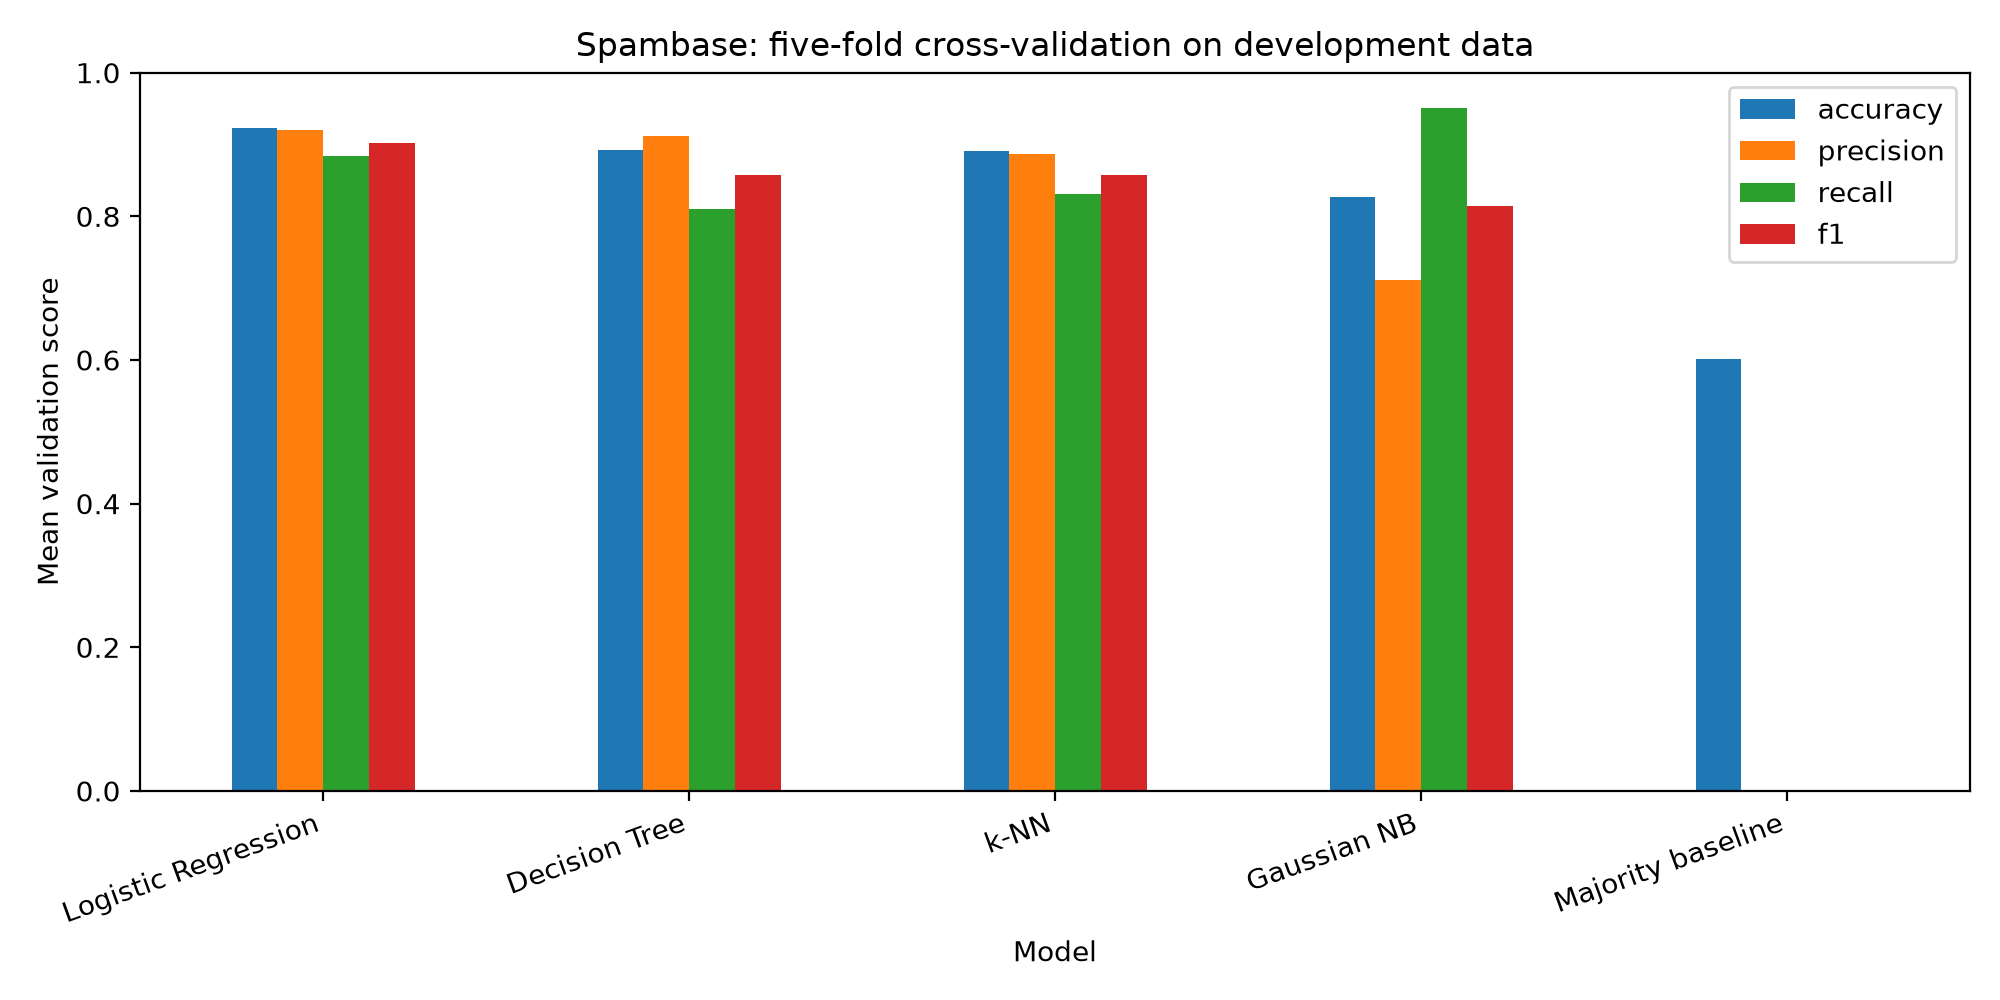

In [ ]:
# Part D: Visualize Model Comparison

import matplotlib.pyplot as plt
from IPython.display import display

metrics = ["accuracy", "precision", "recall", "f1"]

ax = comparison.set_index("model")[metrics].plot(
    kind="bar",
    ylim=(0, 1),
    figsize=(10, 5)
)

ax.set_ylabel("Mean validation score")
ax.set_xlabel("Model")
ax.set_title("Spambase: five-fold cross-validation on development data")

plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "model_comparison.png", dpi=200)

# Notebook mein graph bhi show karein (py version sirf PNG save karta tha).
display(ax.figure)
plt.close()

print("Model comparison graph saved successfully!")

## Cell 8 — Select Best Model & Final Test

**Roman Urdu Explanation:** CV table mein highest F1 wala model automatically select hota hai. `clone()` fresh model banata hai, `.fit()` complete development data par train karta hai, aur `.predict()` reserved test data par result deta hai. Final metrics CSV mein save hoti hain.

In [ ]:
# Part D: Select Best Model and Final Testing

from sklearn.base import clone

# Select model using highest cross-validation F1
selected_name = comparison.iloc[0]["model"]

# Create fresh model
selected_model = clone(models[selected_name])

# Train on complete development data
selected_model.fit(X_dev, y_dev)

# Predict on final test data
test_predictions = selected_model.predict(X_test)

print("Selected using CV only:", selected_name)

# Calculate final test metrics
final_metrics = pd.DataFrame([{
    "model": selected_name,
    "accuracy": accuracy_score(y_test, test_predictions),
    "precision": precision_score(y_test, test_predictions, zero_division=0),
    "recall": recall_score(y_test, test_predictions, zero_division=0),
    "f1": f1_score(y_test, test_predictions, zero_division=0),
}])

print(final_metrics.round(3).to_string(index=False))

# Save final results
final_metrics.to_csv(
    REPORTS_DIR / "final_test_metrics.csv",
    index=False
)

print("Final test metrics saved successfully!")

Selected using CV only: Logistic Regression
              model  accuracy  precision  recall    f1
Logistic Regression     0.924      0.908     0.9 0.904
Final test metrics saved successfully!


## Cell 9 — Confusion Matrix

**Roman Urdu Explanation:** Ye cell correct aur incorrect predictions ko 4 categories mein count karta hai: `TN` genuine email sahi, `FP` genuine ko spam, `FN` spam miss, aur `TP` spam sahi detect. Output `reports/confusion_matrix.csv` mein save hota hai.

In [ ]:
# Step 11: Confusion Matrix

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    test_predictions,
    labels=[0, 1]
)

tn, fp, fn, tp = cm.ravel()

assert cm.sum() == len(y_test)

print("Rows = actual; columns = predicted; label order = [0, 1]")
print(cm)
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

pd.DataFrame(
    cm,
    index=["actual_0", "actual_1"],
    columns=["pred_0", "pred_1"]
).to_csv(
    REPORTS_DIR / "confusion_matrix.csv"
)

print("Confusion matrix saved successfully!")

Rows = actual; columns = predicted; label order = [0, 1]
[[594  38]
 [ 42 377]]
TN=594, FP=38, FN=42, TP=377
Confusion matrix saved successfully!


## Cell 10 — Save & Reload Trained Model

**Roman Urdu Explanation:** `joblib.dump()` trained model ko `models/spam_predictor.joblib` mein save karta hai. `joblib.load()` dobara load karta hai aur `np.array_equal()` se verify hota hai ke predictions bilkul same hain. Sirf trusted joblib files load karna.

In [ ]:
# Part E: Save and Reload Trained Model

import joblib
import sklearn

bundle_path = MODELS_DIR / "spam_predictor.joblib"

bundle = {
    "model": selected_model,
    "features": FEATURES,
    "target_mapping": {0: "legitimate", 1: "spam"},
    "selected_name": selected_name,
    "sklearn_version": sklearn.__version__,
}

# Save trained model
joblib.dump(bundle, bundle_path)

# Reload saved model
loaded = joblib.load(bundle_path)

# Verify predictions
reloaded_predictions = loaded["model"].predict(
    X_test[loaded["features"]]
)

assert np.array_equal(reloaded_predictions, test_predictions)

print("Saved and verified:", bundle_path)

Saved and verified: week10/models/spam_predictor.joblib


## Cell 11 — Predict One Test Email

**Roman Urdu Explanation:** Test set ki pehli email ke 57 numerical features liye jate hain aur saved model prediction karta hai. Phir predicted label ko actual label se compare karte hain. Ye sirf demo hai, naya test ya model selection nahi.

In [ ]:
# Part E: Test One Email Prediction

# Select one email from the held-out test dataset
new_email = X_test.iloc[[0]].copy()

# Arrange all 57 features in the saved order
aligned = new_email[loaded["features"]]

# Predict using the saved model
prediction = int(loaded["model"].predict(aligned)[0])

# Show predicted and actual labels
print("Predicted:", loaded["target_mapping"][prediction])
print("Actual:", loaded["target_mapping"][int(y_test.iloc[0])])

Predicted: legitimate
Actual: legitimate
